# Contraction-overlap safety threshold validation

This notebook closes the preliminary validation of the instantaneous-contraction safety threshold $\xi_{\rm safe}$.

We compare

$$
\xi_{\rm safe}\in\left\{e^{-1},\,e^{-1/2},\,0.8\right\}
$$

with the final production protocol:

- $N=1000$;
- $\rho\in\{0.75,0.80,0.84,0.90\}$;
- 64 realizations per density;
- $\lambda_{\rm core}=1$;
- $\Delta t=0.01$;
- $n_{\rm int}=5$;
- no noise;
- initially round cells;
- morphology updated once per integration step;
- $T=2000$.

The purpose is not to define a convergence limit in $\xi_{\rm safe}$. The safety rule should prevent pathological post-contraction overlaps while intervening as little as possible in the morphology dynamics.

Late-time quantities are evaluated over $1500\le t\le2000$. Time averages are first computed for each realization and ensemble statistics are then obtained across the 64 realizations.

In [15]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.precision", 5)

candidate_roots = [
    Path("processed"),
    Path("preliminary/xi_safe/processed"),
]

PROCESSED_ROOT = next((p.resolve() for p in candidate_roots if p.exists()), None)
if PROCESSED_ROOT is None:
    raise FileNotFoundError(
        "Expected ./processed or ./preliminary/xi_safe/processed."
    )

ANALYSIS_ROOT = PROCESSED_ROOT.parent
FIGURE_DIR = ANALYSIS_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CASES = {
    "exp_m1": (float(np.exp(-1)), r"$e^{-1}$"),
    "exp_mhalf": (float(np.exp(-0.5)), r"$e^{-1/2}$"),
    "xi_0_8": (0.8, r"$0.8$"),
}

XI_ORDER = [value for value, _ in CASES.values()]
XI_LABELS = {value: label for value, label in CASES.values()}
RHO_ORDER = [0.75, 0.80, 0.84, 0.90]

LATE_TMIN = 1500.0
LATE_TMAX = 2000.0

print("Processed root:", PROCESSED_ROOT)
print("Figures:", FIGURE_DIR)


Processed root: /home/usuario/Documentos/oncostreams/oncostreams_model_analysis/preliminary/xi_safe/processed
Figures: /home/usuario/Documentos/oncostreams/oncostreams_model_analysis/preliminary/xi_safe/figures


## 1. Load and verify the campaign

Only the observables needed to decide $\xi_{\rm safe}$ are retained: the elongated fraction, deformation events, and overlap diagnostics.

In [16]:
metadata_rows = []

for case, (xi_safe, _) in CASES.items():
    with (PROCESSED_ROOT / case / "campaign_metadata.json").open() as handle:
        meta = json.load(handle)

    metadata_rows.append({
        "case": case,
        "xi_safe": meta["contraction_overlap_safety_ratio"],
        "delta_t": meta["delta_t"],
        "lambda_core": meta["lambda_core"],
        "n_int": meta["cell_max_def_attempts"],
        "deformation_attempt_period": meta["deformation_attempt_period"],
        "deformation_interval_steps": meta["deformation_interval_steps"],
        "N": meta["N"],
        "realizations": meta["realizations_per_density"],
        "final_time": meta["final_time"],
        "master_seed": meta["master_seed"],
        "git_commit": meta["code_provenance"]["git_commit"],
    })

metadata = pd.DataFrame(metadata_rows)
display(metadata)

assert np.allclose(metadata["delta_t"], 0.01)
assert np.allclose(metadata["lambda_core"], 1.0)
assert (metadata["n_int"] == 5).all()
assert metadata["deformation_attempt_period"].isna().all()
assert (metadata["deformation_interval_steps"] == 1).all()
assert (metadata["N"] == 1000).all()
assert (metadata["realizations"] == 64).all()
assert np.allclose(metadata["final_time"], 2000.0)
assert metadata["master_seed"].nunique() == 1

for case, (xi_safe, _) in CASES.items():
    measured = metadata.loc[metadata["case"] == case, "xi_safe"].iloc[0]
    assert np.isclose(measured, xi_safe)

print("Campaign metadata checks passed.")


,case,xi_safe,delta_t,lambda_core,n_int,deformation_attempt_period,deformation_interval_steps,N,realizations,final_time,master_seed,git_commit
0,exp_m1,0.36788,0.01,1.0,5,None,1,1000,64,2000.0,179721305894280118117630397609131881617,16d299e7a533dc79acb01c8037f98c25af696125
1,exp_mhalf,0.60653,0.01,1.0,5,None,1,1000,64,2000.0,179721305894280118117630397609131881617,16d299e7a533dc79acb01c8037f98c25af696125
2,xi_0_8,0.80000,0.01,1.0,5,None,1,1000,64,2000.0,179721305894280118117630397609131881617,16d299e7a533dc79acb01c8037f98c25af696125


Campaign metadata checks passed.


In [17]:
def load_case_table(case, relative_path):
    path = PROCESSED_ROOT / case / "processed" / relative_path
    df = pd.read_parquet(path).copy()
    df["case"] = case
    df["xi_safe"] = CASES[case][0]
    return df

order = pd.concat(
    [load_case_table(case, "order_parameters/order_parameters.parquet") for case in CASES],
    ignore_index=True,
)

deformation = pd.concat(
    [load_case_table(case, "deformation/deformation.parquet") for case in CASES],
    ignore_index=True,
)

overlap = pd.concat(
    [load_case_table(case, "overlap/overlap.parquet") for case in CASES],
    ignore_index=True,
)

for name, df in {
    "order": order,
    "deformation": deformation,
    "overlap": overlap,
}.items():
    counts = df.groupby(["case", "rho"])["seed"].nunique()
    assert (counts == 64).all()
    assert set(np.round(df["rho"].unique(), 8)) == set(RHO_ORDER)

print("Processed-data checks passed.")


Processed-data checks passed.


## 2. Fraction of elongated cells

If the safety threshold is too strict, mechanically requested contractions are blocked and elongated cells accumulate. The first diagnostic is therefore $f_E(t)$.

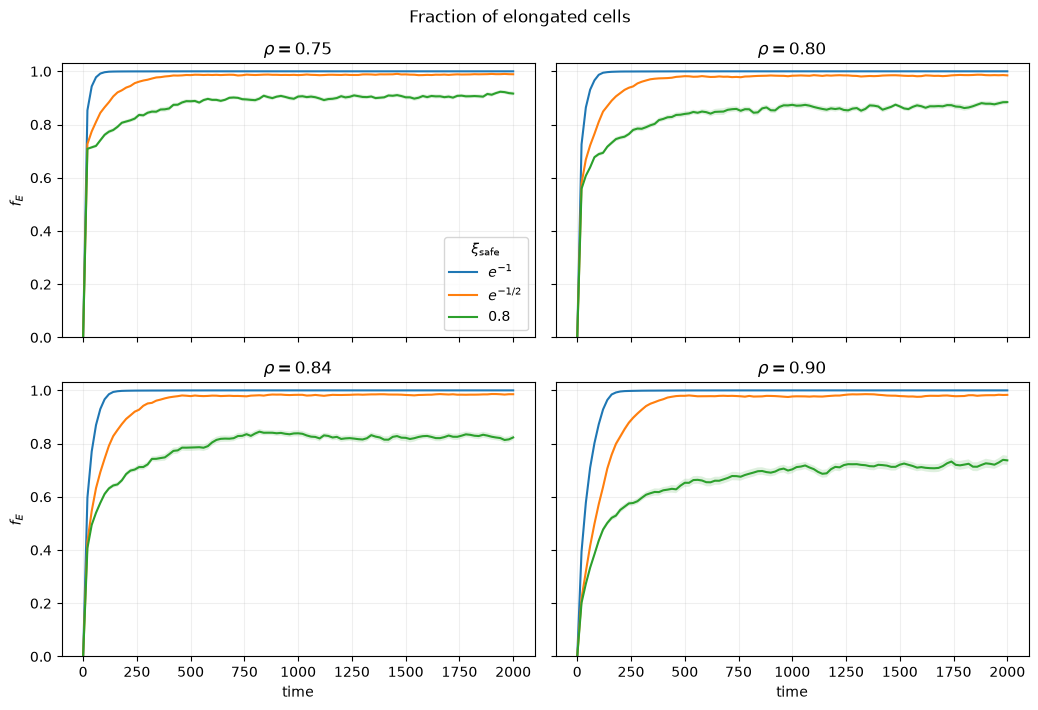

In [18]:
f_time = (
    order.groupby(["xi_safe", "rho", "time"], as_index=False)
    .agg(
        mean=("fraction_elongated", "mean"),
        sem=("fraction_elongated", lambda x: x.std(ddof=1) / np.sqrt(x.count())),
    )
)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), sharex=True, sharey=True)

for ax, rho in zip(axes.flat, RHO_ORDER):
    d_rho = f_time[np.isclose(f_time["rho"], rho)]

    for xi in XI_ORDER:
        d = d_rho[np.isclose(d_rho["xi_safe"], xi)]
        ax.plot(d["time"], d["mean"], label=XI_LABELS[xi])
        ax.fill_between(
            d["time"],
            d["mean"] - d["sem"],
            d["mean"] + d["sem"],
            alpha=0.15,
        )

    ax.set_title(rf"$\rho={rho:.2f}$")
    ax.set_ylim(0, 1.03)
    ax.grid(alpha=0.2)

for ax in axes[-1, :]:
    ax.set_xlabel("time")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$f_E$")

axes[0, 0].legend(title=r"$\xi_{\rm safe}$")
fig.suptitle("Fraction of elongated cells")
fig.tight_layout()

fig.savefig(FIGURE_DIR / "fraction_elongated_time_series.png", dpi=200, bbox_inches="tight")
plt.show()


## 3. How intrusive is the safety rule?

For every realization, all deformation intervals within the late-time window are aggregated. The rejected-contraction fraction is

$$
r_{\rm reject}
=
\frac{N_{\rm rejected}}
{N_{\rm accepted}+N_{\rm rejected}}.
$$

A safety guard should keep this fraction small. The accepted-contraction and successful-elongation rates are shown together to verify the late-time morphology turnover.

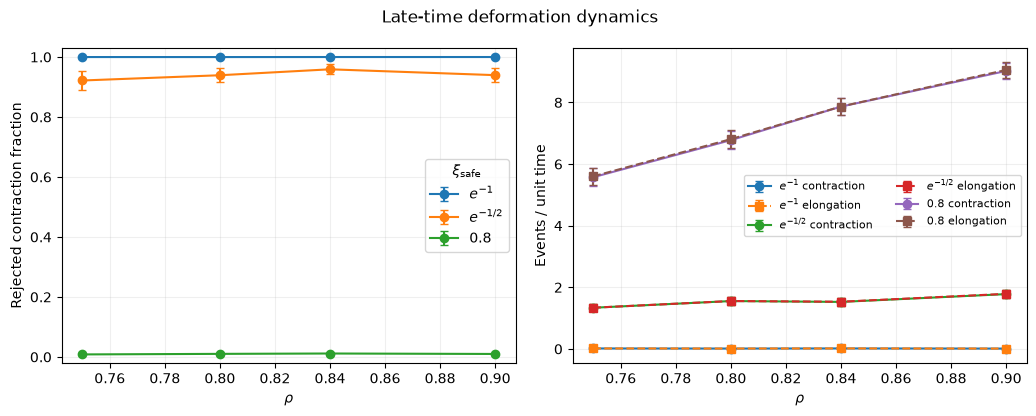

In [19]:
def summarize_realizations(df, value_columns):
    rows = []
    for (xi, rho), group in df.groupby(["xi_safe", "rho"]):
        row = {"xi_safe": xi, "rho": rho, "n": group["seed"].nunique()}
        for col in value_columns:
            row[f"{col}_mean"] = group[col].mean()
            row[f"{col}_sem"] = group[col].std(ddof=1) / np.sqrt(group[col].count())
        rows.append(row)
    return pd.DataFrame(rows).sort_values(["xi_safe", "rho"]).reset_index(drop=True)


def_late = deformation[
    (deformation["time_start"] >= LATE_TMIN)
    & (deformation["time_end"] <= LATE_TMAX)
].copy()

def_real = (
    def_late.groupby(["xi_safe", "rho", "seed"], as_index=False)
    .agg(
        duration=("interval_duration", "sum"),
        contraction_events=("contraction_events", "sum"),
        contraction_overlap_rejections=("contraction_overlap_rejections", "sum"),
        round_elongation_successes=("round_elongation_successes", "sum"),
    )
)

def_real["contraction_attempts"] = (
    def_real["contraction_events"] + def_real["contraction_overlap_rejections"]
)
def_real["rejection_fraction"] = (
    def_real["contraction_overlap_rejections"] / def_real["contraction_attempts"]
)
def_real["contraction_rate"] = def_real["contraction_events"] / def_real["duration"]
def_real["elongation_rate"] = def_real["round_elongation_successes"] / def_real["duration"]

def_summary = summarize_realizations(
    def_real,
    ["rejection_fraction", "contraction_rate", "elongation_rate"],
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

for xi in XI_ORDER:
    d = def_summary[np.isclose(def_summary["xi_safe"], xi)]

    axes[0].errorbar(
        d["rho"],
        d["rejection_fraction_mean"],
        yerr=d["rejection_fraction_sem"],
        marker="o",
        capsize=3,
        label=XI_LABELS[xi],
    )

    axes[1].errorbar(
        d["rho"],
        d["contraction_rate_mean"],
        yerr=d["contraction_rate_sem"],
        marker="o",
        capsize=3,
        label=XI_LABELS[xi] + " contraction",
    )
    axes[1].errorbar(
        d["rho"],
        d["elongation_rate_mean"],
        yerr=d["elongation_rate_sem"],
        marker="s",
        linestyle="--",
        capsize=3,
        label=XI_LABELS[xi] + " elongation",
    )

axes[0].set_xlabel(r"$\rho$")
axes[0].set_ylabel("Rejected contraction fraction")
axes[0].set_ylim(-0.02, 1.03)
axes[0].grid(alpha=0.2)
axes[0].legend(title=r"$\xi_{\rm safe}$")

axes[1].set_xlabel(r"$\rho$")
axes[1].set_ylabel("Events / unit time")
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8, ncol=2)

fig.suptitle("Late-time deformation dynamics")
fig.tight_layout()

fig.savefig(FIGURE_DIR / "deformation_dynamics_vs_xi_safe.png", dpi=200, bbox_inches="tight")
plt.show()


## 4. What overlaps does the guard remove?

The safety check acts on the maximum normalized overlap that would result after an instantaneous contraction. We compare the extreme proposed and accepted overlaps with the ordinary mean overlap of the evolving system.

The desired behavior is selective: the guard should cut the extreme post-contraction tail without strongly changing the typical overlap state.

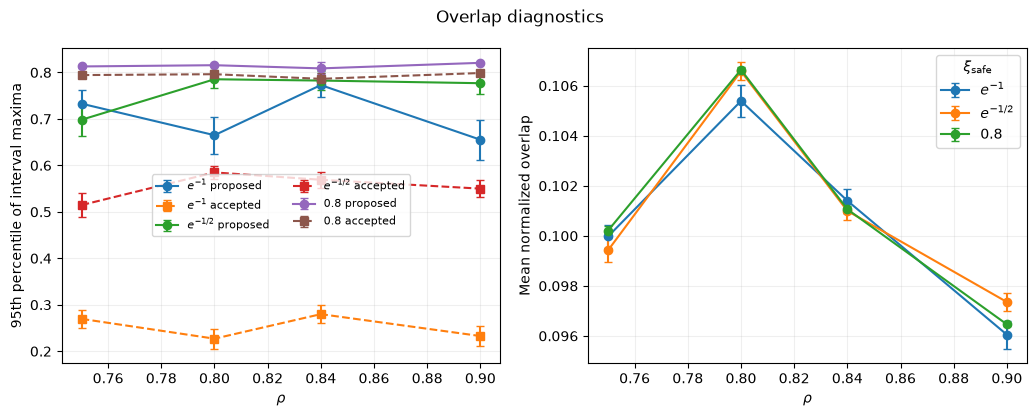

In [20]:
contraction_overlap_real = (
    def_late.groupby(["xi_safe", "rho", "seed"])
    .agg(
        proposed_p95=(
            "max_contraction_proposed_overlap",
            lambda x: x.quantile(0.95),
        ),
        accepted_p95=(
            "max_contraction_accepted_overlap",
            lambda x: x.quantile(0.95),
        ),
    )
    .reset_index()
)

contraction_overlap_summary = summarize_realizations(
    contraction_overlap_real,
    ["proposed_p95", "accepted_p95"],
)

overlap_late = overlap[
    (overlap["time_start"] >= LATE_TMIN)
    & (overlap["time_end"] <= LATE_TMAX)
].copy()

global_overlap_real = (
    overlap_late.groupby(["xi_safe", "rho", "seed"], as_index=False)
    .agg(mean_overlap=("mean_normalized_overlap", "mean"))
)

global_overlap_summary = summarize_realizations(
    global_overlap_real,
    ["mean_overlap"],
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

for xi in XI_ORDER:
    d = contraction_overlap_summary[
        np.isclose(contraction_overlap_summary["xi_safe"], xi)
    ]

    axes[0].errorbar(
        d["rho"],
        d["proposed_p95_mean"],
        yerr=d["proposed_p95_sem"],
        marker="o",
        capsize=3,
        label=XI_LABELS[xi] + " proposed",
    )
    axes[0].errorbar(
        d["rho"],
        d["accepted_p95_mean"],
        yerr=d["accepted_p95_sem"],
        marker="s",
        linestyle="--",
        capsize=3,
        label=XI_LABELS[xi] + " accepted",
    )

for xi in XI_ORDER:
    d = global_overlap_summary[
        np.isclose(global_overlap_summary["xi_safe"], xi)
    ]
    axes[1].errorbar(
        d["rho"],
        d["mean_overlap_mean"],
        yerr=d["mean_overlap_sem"],
        marker="o",
        capsize=3,
        label=XI_LABELS[xi],
    )

axes[0].set_xlabel(r"$\rho$")
axes[0].set_ylabel("95th percentile of interval maxima")
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=8, ncol=2)

axes[1].set_xlabel(r"$\rho$")
axes[1].set_ylabel("Mean normalized overlap")
axes[1].grid(alpha=0.2)
axes[1].legend(title=r"$\xi_{\rm safe}$")

fig.suptitle("Overlap diagnostics")
fig.tight_layout()

fig.savefig(FIGURE_DIR / "overlap_diagnostics_vs_xi_safe.png", dpi=200, bbox_inches="tight")
plt.show()


## 5. Compact summary

The decisive quantity is the fraction of mechanically requested contractions rejected by the safety rule. We also report the late-time elongated fraction for context.

In [21]:
late_f = (
    order[order["time"].between(LATE_TMIN, LATE_TMAX)]
    .groupby(["xi_safe", "rho", "seed"], as_index=False)
    .agg(fraction_elongated=("fraction_elongated", "mean"))
)

late_f_summary = summarize_realizations(
    late_f,
    ["fraction_elongated"],
)

summary = (
    def_summary[
        ["xi_safe", "rho", "rejection_fraction_mean"]
    ]
    .merge(
        late_f_summary[
            ["xi_safe", "rho", "fraction_elongated_mean"]
        ],
        on=["xi_safe", "rho"],
        validate="one_to_one",
    )
)

summary["xi_safe"] = summary["xi_safe"].map(XI_LABELS)
summary["rejected_contractions_percent"] = (
    100 * summary["rejection_fraction_mean"]
)

display(
    summary[
        [
            "xi_safe",
            "rho",
            "rejected_contractions_percent",
            "fraction_elongated_mean",
        ]
    ].round(4)
)


,xi_safe,rho,rejected_contractions_percent,fraction_elongated_mean
0,$e^{-1}$,0.75,99.9864,1.0000
1,$e^{-1}$,0.80,99.9807,1.0000
2,$e^{-1}$,0.84,99.9929,1.0000
3,$e^{-1}$,0.90,99.9938,1.0000
4,$e^{-1/2}$,0.75,92.1687,0.9881
5,$e^{-1/2}$,0.80,93.9201,0.9845
6,$e^{-1/2}$,0.84,95.8973,0.9843
7,$e^{-1/2}$,0.90,93.9515,0.9798
8,$0.8$,0.75,0.8414,0.9082
9,$0.8$,0.80,1.0265,0.8709


## 6. Conclusion

The three thresholds do not act as equivalent numerical safeguards.

- $\xi_{\rm safe}=e^{-1}$ rejects essentially all mechanically requested contractions and drives $f_E$ to unity.
- $\xi_{\rm safe}=e^{-1/2}$ remains strongly intrusive: most contraction attempts are still rejected and the system remains almost fully elongated.
- $\xi_{\rm safe}=0.8$ rejects only about one percent of contraction attempts. At the same time, it still removes the extreme post-contraction overlap tail, while the ordinary mean-overlap level remains comparable to the stricter cases.

The strict thresholds therefore become an additional morphology rule rather than a passive safety condition.

We adopt

$$
\boxed{\xi_{\rm safe}=0.8}.
$$

Together with

$$
\lambda_{\rm core}=1,\qquad
\Delta t=0.01,\qquad
n_{\rm int}=5,
$$

and one morphology update per integration step, this closes the preliminary model-protocol validation. Simulation duration and late-time windows will be checked within each subsequent physical campaign rather than treated as universal model parameters.